# Supplementary Figure S9. Temporal trends in RNA structural quality

Ported from the backup repo's figS9.


In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if base.name.startswith("PARSE-RNA-Analysis") and (base / "data").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["parse", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["FastRNA", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNET"]

def finish(ax):
    """House chrome: all four spines, thin, outward ticks, no grid."""
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    """Unambiguous, scored per-pair records."""
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    """Resolution for either method.

    The EM keys carry a non-ASCII Angstrom sign; looking for "(A)" instead drops
    every cryo-EM structure silently.
    """
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_PARSE_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["parse_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["parse_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    """A small-multiples grid of histograms inside one gridspec cell."""
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes


## Panel setup
Per-structure table with deposition year


In [2]:
from datetime import datetime
from scipy.stats import linregress

METHOD_COLOR = {"X-ray": BLUE, "EM": ORANGE}
METHOD_LABEL = {"X-ray": "X-ray", "EM": "cryo-EM"}

def _year(s):
    try:
        return datetime.fromisoformat(s).year
    except Exception:
        return None

def temporal_df():
    df = structure_scores()
    df = df[df.method.isin(["X-ray", "EM"])].copy()
    df["year"] = df["deposited"].map(lambda s: _year(s) if isinstance(s, str) else None)
    df = df.dropna(subset=["year", "resolution", "pairs_score"])
    df = df[(df.resolution > 0) & (df.n_pairs >= 5)]
    return df.astype({"year": int}).reset_index(drop=True)

TEMPORAL = temporal_df()
YEARLY = (TEMPORAL.groupby(["method", "year"])
          .agg(resolution_mean=("resolution", "mean"), resolution_sem=("resolution", "sem"),
               pairs_mean=("pairs_score", "mean"), pairs_sem=("pairs_score", "sem"),
               n=("pdb", "count")).reset_index().sort_values(["method", "year"]).fillna(0))
EM = TEMPORAL[TEMPORAL.method == "EM"]
print(f"{len(TEMPORAL):,} structures, {TEMPORAL.year.min()}-{TEMPORAL.year.max()} | "
      f"cryo-EM {len(EM):,}")

MIN_PER_YEAR = 10

def trend(ax, mean_col, sem_col, ylabel, unit, invert_y=False, legend_loc="best"):
    for method in ("X-ray", "EM"):
        sub = YEARLY[YEARLY.method == method].sort_values("year")
        sub = sub[sub.n >= MIN_PER_YEAR]
        if sub.empty:
            continue
        c = METHOD_COLOR[method]
        lab = METHOD_LABEL[method]
        if len(sub) >= 3:
            r = linregress(sub.year, sub[mean_col])
            xs = np.linspace(sub.year.min(), sub.year.max(), 50)
            ax.plot(xs, r.slope * xs + r.intercept, "--", color=c, lw=1.0, alpha=0.9,
                    zorder=1)
            lab = f"{lab} ({r.slope:+.3f} {unit})"
        ax.errorbar(sub.year, sub[mean_col], yerr=sub[sem_col], fmt="o-", color=c, ecolor=c,
                    capsize=2, markersize=4, lw=0.7, elinewidth=0.8, label=lab, zorder=2)
    if invert_y:
        ax.invert_yaxis()
    ax.set_xlabel("Deposition year")
    ax.set_ylabel(ylabel)
    ax.legend(loc=legend_loc)
    finish(ax)


1,883 structures, 1990-2025 | cryo-EM 824


## Panel A
Average experimental resolution by deposition year


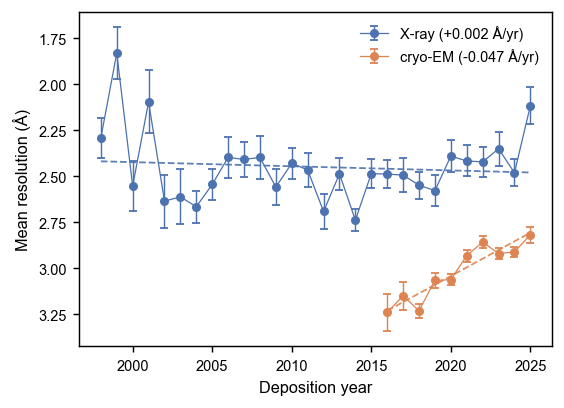

In [3]:
def draw_a(ax):
    trend(ax, "resolution_mean", "resolution_sem", "Mean resolution (\u00c5)",
          "\u00c5/yr", invert_y=True)


fig, ax = plt.subplots(figsize=(4.4, 3.2))
draw_a(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS9_A_resolution_by_year.png")
plt.show()


## Panel B
Average base-pair quality score by deposition year


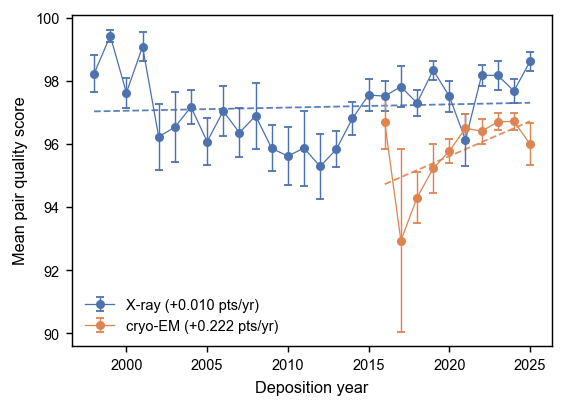

In [4]:
def draw_b(ax):
    trend(ax, "pairs_mean", "pairs_sem", "Mean pair quality score", "pts/yr",
          legend_loc="lower left")
    ax.set_ylim(bottom=89.6)


fig, ax = plt.subplots(figsize=(4.4, 3.2))
draw_b(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS9_B_score_by_year.png")
plt.show()


## Panel C
Score trends over time within fixed cryo-EM resolution bands


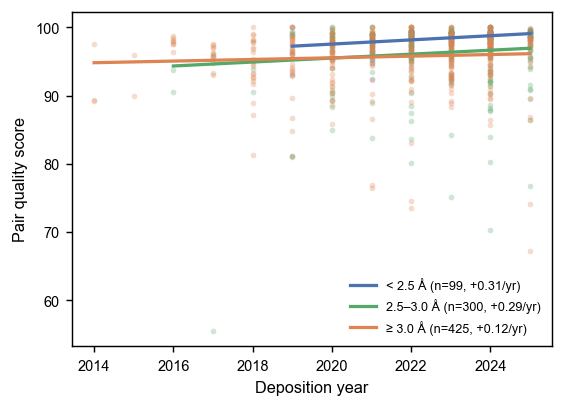

In [5]:
BANDS = [(0, 2.5), (2.5, 3.0), (3.0, np.inf)]
BAND_COLORS = [BLUE, GREEN, ORANGE]

def draw_c(ax):
    yr = EM.year.to_numpy(float); res = EM.resolution.to_numpy(float)
    ps = EM.pairs_score.to_numpy(float)
    for (lo, hi), c in zip(BANDS, BAND_COLORS):
        m = (res >= lo) & (res < hi)
        if m.sum() < 15:
            continue
        slope, b = np.polyfit(yr[m], ps[m], 1)
        ax.scatter(yr[m], ps[m], s=10, alpha=0.28, color=c, linewidths=0)
        xs = np.linspace(yr[m].min(), yr[m].max(), 50)
        band = (f"< {hi:.1f}" if lo == 0 else
                f"\u2265 {lo:.1f}" if np.isinf(hi) else f"{lo:.1f}\u2013{hi:.1f}")
        ax.plot(xs, slope * xs + b, color=c, lw=1.8,
                label=f"{band} \u00c5 (n={m.sum()}, {slope:+.2f}/yr)")
    ax.set_xlabel("Deposition year")
    ax.set_ylabel("Pair quality score")
    ax.legend(loc="lower right", fontsize=7)
    finish(ax)


fig, ax = plt.subplots(figsize=(4.4, 3.2))
draw_c(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS9_C_trend_within_bands.png")
plt.show()


## Panel D
Partial regression of cryo-EM score against year, resolution removed


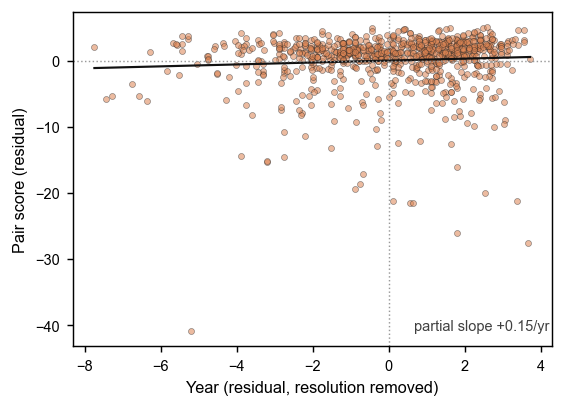

In [6]:
def draw_d(ax):
    yr = EM.year.to_numpy(float); res = EM.resolution.to_numpy(float)
    ps = EM.pairs_score.to_numpy(float)
    def resid(v, ctrl):
        X = np.column_stack([np.ones(len(v)), ctrl - ctrl.mean()])
        beta, *_ = np.linalg.lstsq(X, v, rcond=None)
        return v - X @ beta
    ry, rp = resid(yr, res), resid(ps, res)
    slope, b = np.polyfit(ry, rp, 1)
    ax.scatter(ry, rp, s=11, facecolor=METHOD_COLOR["EM"], edgecolor="0.15", linewidths=0.35, alpha=0.55)
    xs = np.linspace(ry.min(), ry.max(), 50)
    ax.plot(xs, slope * xs + b, color=FIT, lw=1.2)
    ax.axhline(0, color="0.6", lw=0.8, ls=":")
    ax.axvline(0, color="0.6", lw=0.8, ls=":")
    ax.text(0.995, 0.04, f"partial slope {slope:+.2f}/yr", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=8, color="0.25")
    ax.set_xlabel("Year (residual, resolution removed)")
    ax.set_ylabel("Pair score (residual)")
    finish(ax)


fig, ax = plt.subplots(figsize=(4.4, 3.2))
draw_d(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS9_D_partial_regression.png")
plt.show()


## Combined figure


text scaled x1.31: 7 pt prints at 7.0 pt at page width


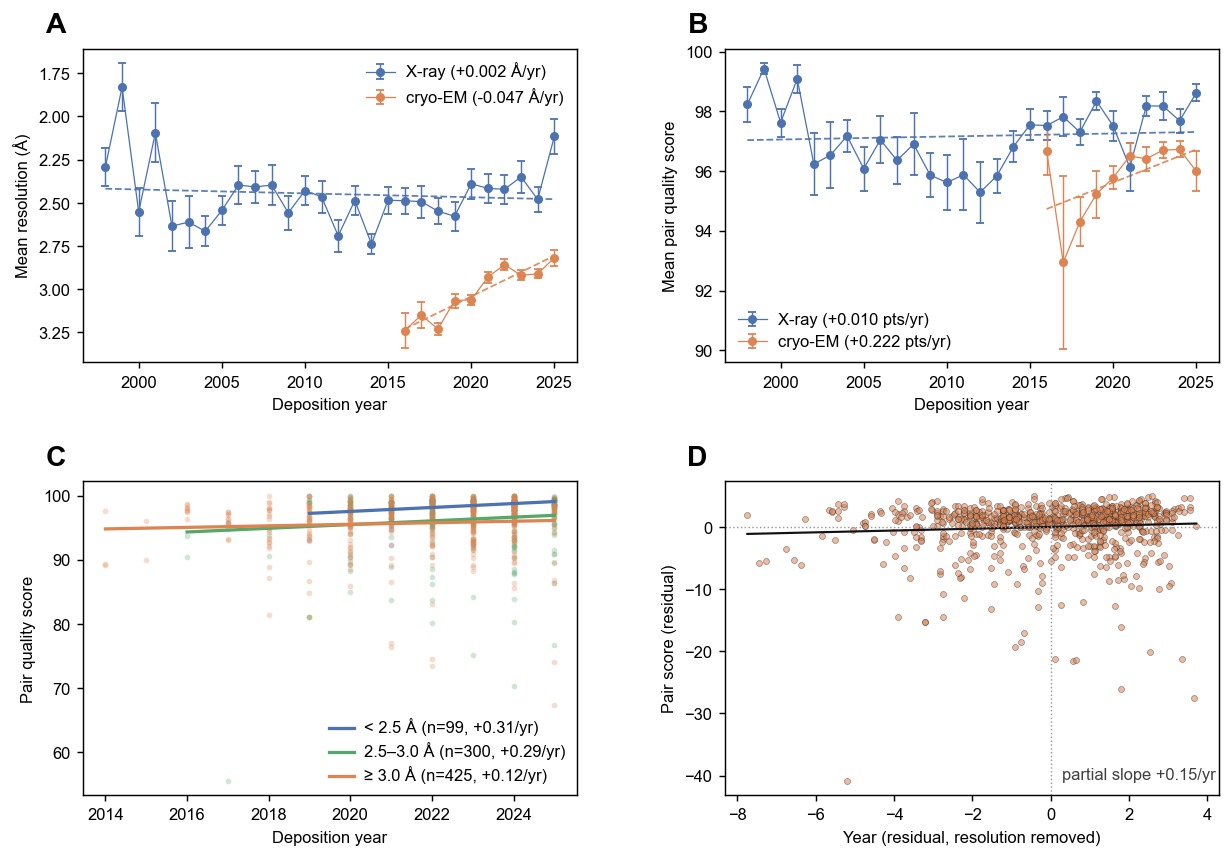

In [7]:
fig = plt.figure(figsize=(9.6, 6.6))
gs = fig.add_gridspec(2, 2, wspace=0.30, hspace=0.38,
                      left=0.075, right=0.985, top=0.95, bottom=0.08)
ax_a = fig.add_subplot(gs[0, 0]); ax_b = fig.add_subplot(gs[0, 1])
ax_c = fig.add_subplot(gs[1, 0]); ax_d = fig.add_subplot(gs[1, 1])
draw_a(ax_a); draw_b(ax_b); draw_c(ax_c); draw_d(ax_d)
for ax, s in ((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D")):
    letter(fig, ax, s)
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
import matplotlib.text as _mtext
def _print_scale(fig, page_in=7.2, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s * 7.2 / (_print_scale(fig) * 7.2):.1f} pt "
      f"at page width")
save(fig, "figures/supplemental/figS9.png")
plt.show()
